<a href="https://colab.research.google.com/github/abbbymuaa/mssp6070/blob/main/Assignments/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'abbbymuaa'
repository = 'mssp6070'
repo_url = f'https://github.com/{owner}/{repository}'
repo_path = Path('') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Current directory: /content/mssp6070
Files in repository:


In [3]:
import pandas as pd
from google.colab import files

df = pd.read_csv("/content/mssp6070/data/InternetSales.csv", encoding="latin1")

#check the size and structure of the dataset
print("Dataset Shape:", df.shape)

#check column names and data types
df.info()

#check missing values
print(df.isnull().sum())

#convert OrderDate to datetime
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

#extract year
df["Year"] = df["OrderDate"].dt.year

#display descriptive statistics
df.describe()


/tmp/ipykernel_6572/1436290740.py:4: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/mssp6070/data/InternetSales.csv", encoding="latin1")


Dataset Shape: (60398, 60)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 60 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        60398 non-null  int64  
 1   CustomerKey               60398 non-null  int64  
 2   GeographyKey              60398 non-null  int64  
 3   City                      60398 non-null  object 
 4   CountryRegionCode         60398 non-null  object 
 5   EnglishCountryRegionName  60398 non-null  object 
 6   CustomerAlternateKey      60398 non-null  object 
 7   Title                     307 non-null    object 
 8   FirstName                 60398 non-null  object 
 9   MiddleName                34903 non-null  object 
 10  LastName                  60398 non-null  object 
 11  NameStyle                 60398 non-null  bool   
 12  BirthDate                 60398 non-null  object 
 13  MaritalStatus             60398 no

,ID,CustomerKey,GeographyKey,YearlyIncome,TotalChildren,NumberChildrenAtHome,HouseOwnerFlag,NumberCarsOwned,ProductKey,OrderDateKey,...,DiscountAmount,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,Year
count,60398.00,60398.00,60398.00,60398.00,60398.00,60398.00,60398.00,60398.00,60398.00,60398.00,...,60398.00,60398.00,60398.00,60398.00,60398.00,60398.00,0.00,0.00,60398,60398.00
mean,30198.50,18841.69,230.52,59715.06,1.85,1.08,0.69,1.51,437.56,20129734.93,...,0.00,286.07,286.07,486.09,38.89,12.15,NaN,NaN,2013-06-09 12:21:38.903937024,2012.90
min,0.00,11000.00,2.00,10000.00,0.00,0.00,0.00,0.00,214.00,20101229.00,...,0.00,0.86,0.86,2.29,0.18,0.06,NaN,NaN,2010-12-29 00:00:00,2010.00
25%,15099.25,14003.00,51.00,30000.00,0.00,0.00,0.00,1.00,359.00,20130403.00,...,0.00,2.97,2.97,7.95,0.64,0.20,NaN,NaN,2013-04-03 00:00:00,2013.00
50%,30198.50,18143.00,211.00,60000.00,2.00,0.00,1.00,2.00,479.00,20130714.00,...,0.00,11.22,11.22,29.99,2.40,0.75,NaN,NaN,2013-07-14 00:00:00,2013.00
75%,45297.75,23429.75,329.00,80000.00,3.00,2.00,1.00,2.00,529.00,20131018.00,...,0.00,294.58,294.58,539.99,43.20,13.50,NaN,NaN,2013-10-18 00:00:00,2013.00
max,60397.00,29483.00,654.00,170000.00,5.00,5.00,1.00,4.00,606.00,20140128.00,...,0.00,2171.29,2171.29,3578.27,286.26,89.46,NaN,NaN,2014-01-28 00:00:00,2014.00
std,17435.55,5432.43,192.40,33065.43,1.62,1.59,0.46,1.15,118.09,4745.05,...,0.00,552.46,552.46,928.49,74.28,23.21,NaN,NaN,NaN,0.48


Internet Sales by Country and Year:
Year                         2010       2011       2012       2013     2014
EnglishCountryRegionName                                                   
Australia                20909.78 2563732.25 2128407.46 4339443.38  8507.72
Canada                    3578.27  571571.80  307604.52 1085632.65  9457.62
France                    3399.99  410845.33  648065.54 1578511.80  3195.06
Germany                      0.00  520500.16  608657.98 1761876.36  3277.83
United Kingdom             699.10  550591.22  712700.96 2124007.29  3713.64
United States            14833.90 2458285.17 1437048.73 5462078.86 17542.85


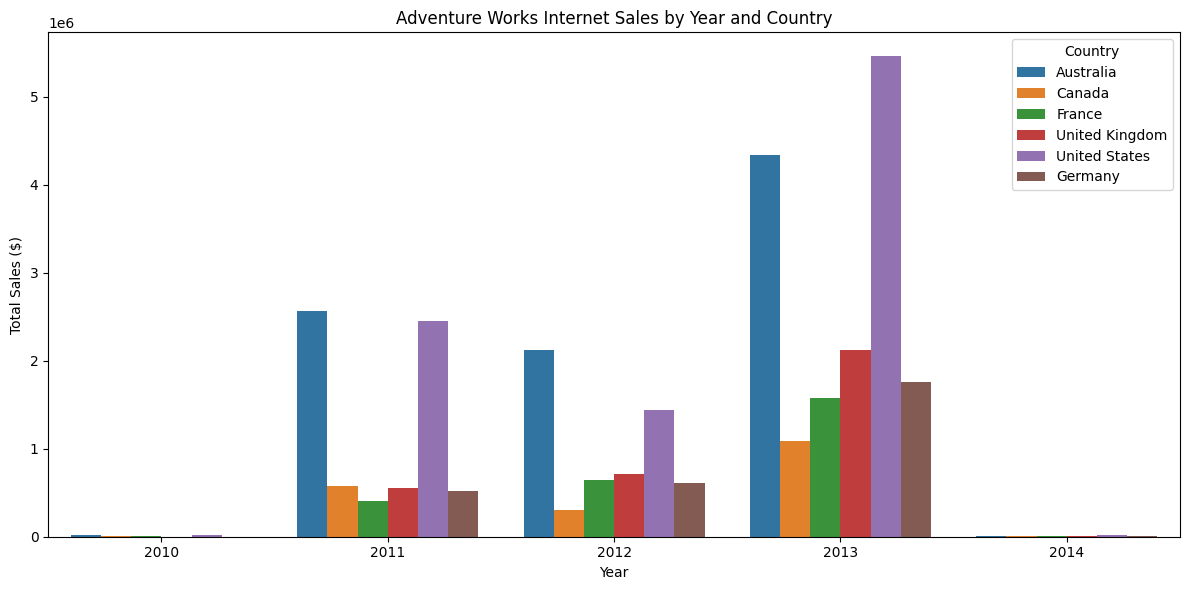

In [5]:
#Q1
#calculate total Internet sales by year and country
sales_by_country_year = df.pivot_table(
    index="EnglishCountryRegionName",
    columns="Year",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

print("Internet Sales by Country and Year:")
print(sales_by_country_year.round(2))

#visualize annual sales by country
annual_country_sales = (
    df.groupby(["Year", "EnglishCountryRegionName"])["SalesAmount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=annual_country_sales,
    x="Year",
    y="SalesAmount",
    hue="EnglishCountryRegionName"
)

plt.title("Adventure Works Internet Sales by Year and Country")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.legend(title="Country")
plt.tight_layout()
plt.show()

Yearly Income Statistics by Country:
                          count     mean    min     max      std
EnglishCountryRegionName                                        
Australia                  3591 64338.62  10000  170000 31830.00
Canada                     1571 57167.41  10000  170000 20251.52
France                     1810 35762.43  10000  110000 27277.40
Germany                    1780 42943.82  10000  130000 35493.58
United Kingdom             1913 52169.37  10000  170000 48431.99
United States              7819 63616.83  10000  170000 25706.48
Gender Distribution by Country:
Gender                       F     M
EnglishCountryRegionName            
Australia                 1777  1814
Canada                     767   804
France                     893   917
Germany                    874   906
United Kingdom             934   979
United States             3888  3931
Gender                       F     M
EnglishCountryRegionName            
Australia                49.48 50.52
Cana

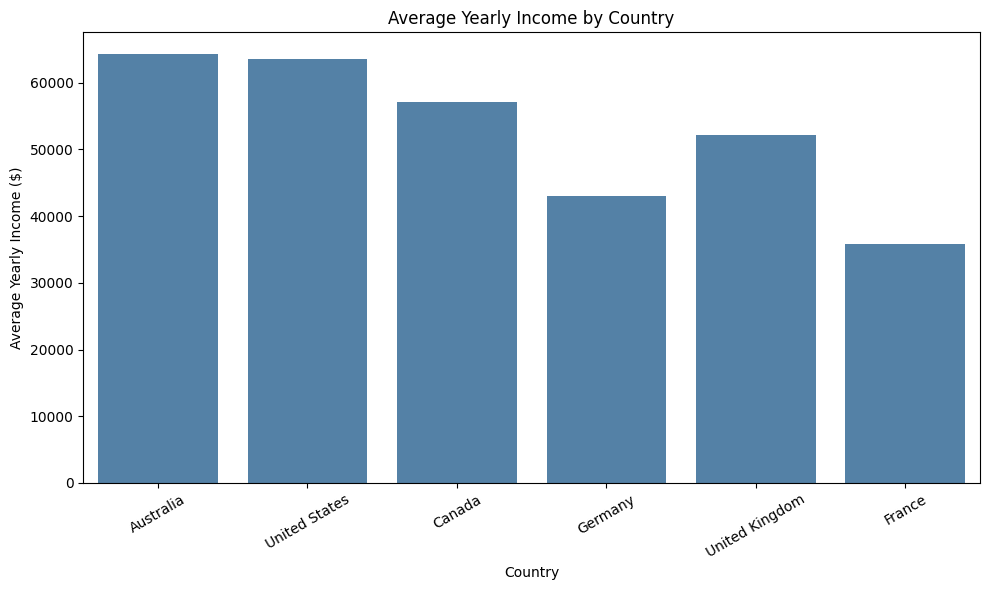

In [8]:
#Q2.
#keep one record per customer
customers = df.drop_duplicates(
    subset="CustomerAlternateKey"
).copy()

#calculate yearly income statistics by country
income_stats = customers.groupby(
    "EnglishCountryRegionName"
)["YearlyIncome"].agg(
    ["count", "mean", "min", "max", "std"]
)

print("Yearly Income Statistics by Country:")
print(income_stats.round(2))

#count female and male customers by country
gender_stats = pd.crosstab(
    customers["EnglishCountryRegionName"],
    customers["Gender"]
)

print("Gender Distribution by Country:")
print(gender_stats)

#calculate gender percentages
gender_percent = pd.crosstab(
    customers["EnglishCountryRegionName"],
    customers["Gender"],
    normalize="index"
) * 100

print(gender_percent.round(2))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=customers,
    x="EnglishCountryRegionName",
    y="YearlyIncome",
    errorbar=None,
    color="steelblue"
)

plt.title("Average Yearly Income by Country")
plt.xlabel("Country")
plt.ylabel("Average Yearly Income ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Total Sales by Product Category:
Category
Bikes         28318144.65
Accessories     700759.96
Clothing        339772.61
Name: SalesAmount, dtype: float64
Highest-Selling Category: Bikes
Average Unit Price: $ 1862.42


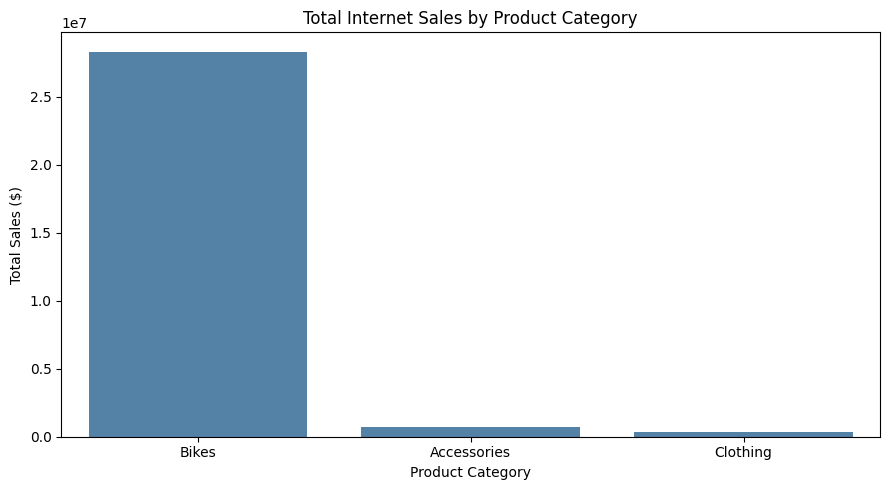

In [9]:
#Q3.
#create product categories based on product names
def categorize_product(name):
    name = str(name)

    if name.startswith(("Mountain-", "Road-", "Touring-")):
        return "Bikes"

    elif any(word in name for word in [
        "Jersey", "Shorts", "Gloves",
        "Socks", "Vest", "Cap"
    ]):
        return "Clothing"

    else:
        return "Accessories"

df["Category"] = df["EnglishProductName"].apply(categorize_product)

#calculate total sales by category
category_sales = (
    df.groupby("Category")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Product Category:")
print(category_sales.round(2))

#identify the highest-selling category
top_category = category_sales.idxmax()

#calculate its average unit price
average_price = df.loc[
    df["Category"] == top_category, "UnitPrice"
].mean()

print("Highest-Selling Category:", top_category)
print("Average Unit Price: $", round(average_price, 2))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    color="steelblue"
)

plt.title("Total Internet Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.show()

Sales by Homeownership:
                       sum  count   mean
HouseOwnerFlag                          
Non-Homeowner   8973327.42  18699 479.88
Homeowner      20385349.80  41699 488.87
Customer Spending by Homeownership:
                count    mean  median     std
HouseOwnerFlag                               
Non-Homeowner    5982 1500.05  209.96 2046.88
Homeowner       12502 1630.57  342.00 2159.07


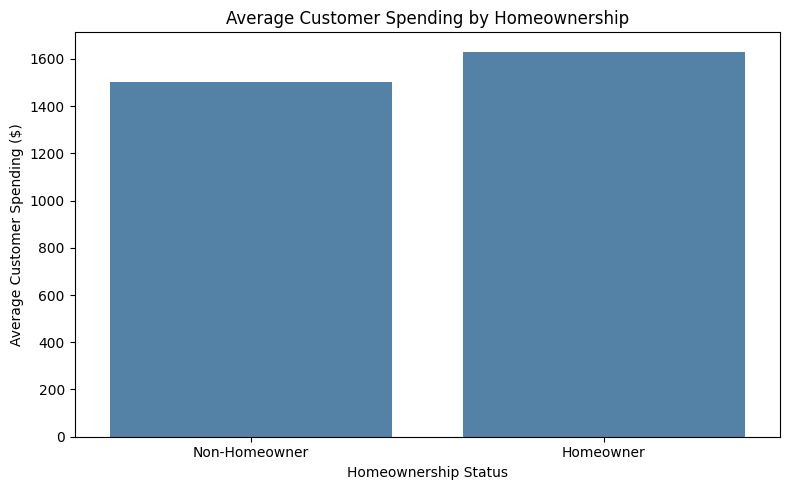

In [10]:
#Q4.
#total sales by homeownership
home_sales = df.groupby("HouseOwnerFlag")["SalesAmount"].agg(
    ["sum", "count", "mean"]
)

home_sales.index = home_sales.index.map({
    0: "Non-Homeowner",
    1: "Homeowner"
})

print("Sales by Homeownership:")
print(home_sales.round(2))
#calculate total spending per customer
customer_spending = df.groupby(
    ["CustomerAlternateKey", "HouseOwnerFlag"],
    as_index=False
)["SalesAmount"].sum()

#compare customer spending
home_comparison = customer_spending.groupby(
    "HouseOwnerFlag"
)["SalesAmount"].agg(
    ["count", "mean", "median", "std"]
)

home_comparison.index = home_comparison.index.map({
    0: "Non-Homeowner",
    1: "Homeowner"
})

print("Customer Spending by Homeownership:")
print(home_comparison.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=customer_spending,
    x="HouseOwnerFlag",
    y="SalesAmount",
    errorbar=None,
    color="steelblue"
)

plt.xticks([0, 1], ["Non-Homeowner", "Homeowner"])
plt.title("Average Customer Spending by Homeownership")
plt.xlabel("Homeownership Status")
plt.ylabel("Average Customer Spending ($)")
plt.tight_layout()
plt.show()

Sales by Year and Product Category:
Category  Accessories       Bikes  Clothing
Year                                       
2010             0.00    43421.04      0.00
2011             0.00  7075525.93      0.00
2012          2147.08  5839695.33    642.79
2013        668241.53 15359502.36 323806.45
2014         30371.35        0.00  15323.37


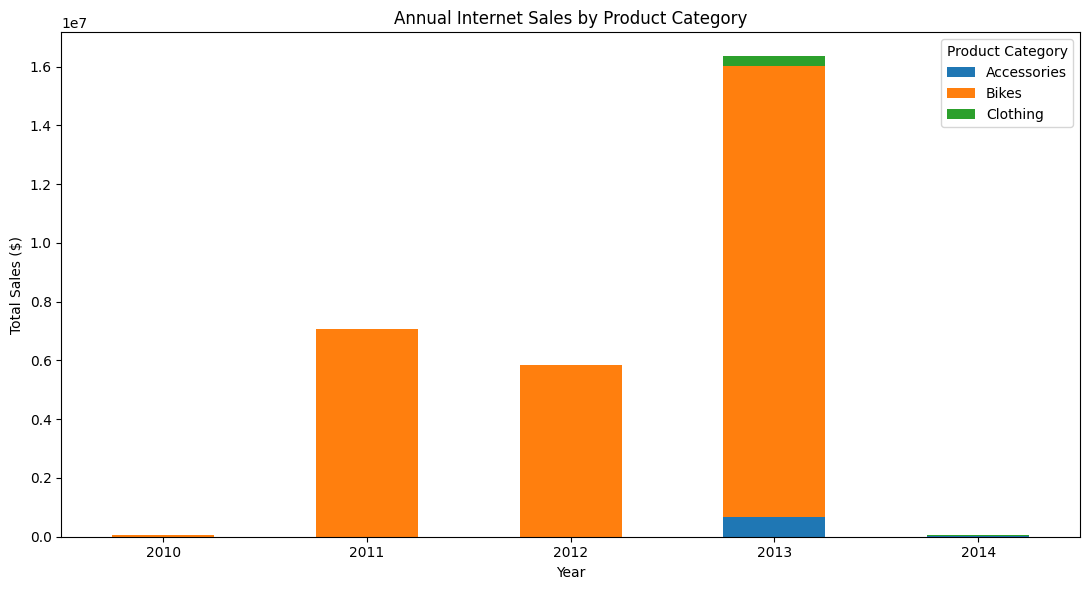

In [11]:
#summarize product category sales by year
sales_by_category_year = df.pivot_table(
    index="Year",
    columns="Category",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

print("Sales by Year and Product Category:")
print(sales_by_category_year.round(2))

#visualize the results
sales_by_category_year.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Annual Internet Sales by Product Category")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.legend(title="Product Category")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()